# 05. Model Experiments & Algorithmic Benchmarking
Comparing 5 regression models on held-out test data (Academic Year 2026–27):
1. Previous-Year Baseline
2. Ridge Regression (SGD/L2 Regularized)
3. Decision Tree Regressor
4. Random Forest Regressor
5. HistGradientBoosting Regressor


In [1]:
# Step 1: Load benchmarking leaderboard
import pandas as pd

df_comp = pd.read_csv('../results/model_comparison.csv')
print('Official Evaluation Leaderboard (Held-Out Test Set: Year 2026-27, N=8,036):')
print(df_comp.to_string(index=False))


Official Evaluation Leaderboard (Held-Out Test Set: Year 2026-27, N=8,036):
                         Model    MAE    MSE   RMSE     R2  Training Time (s)  Prediction Time (s)
     Ridge Regression (SGD/L2) 0.1133 0.0200 0.1415 0.9996              0.120               0.0266
       Random Forest Regressor 0.1168 0.0208 0.1442 0.9996              1.296               0.0820
HistGradientBoosting Regressor 0.1236 0.0260 0.1612 0.9994              3.626               0.0513
       Decision Tree Regressor 0.1266 0.0248 0.1574 0.9995              0.210               0.0302
        Previous-Year Baseline 0.2037 0.0550 0.2346 0.9988              0.000               0.0003


In [1]:
# Step 2: Compare best model (Ridge) vs Baseline
mae_base = df_comp.loc[df_comp['Model'] == 'Previous-Year Baseline', 'MAE'].values[0]
mae_ridge = df_comp.loc[df_comp['Model'] == 'Ridge Regression (SGD/L2)', 'MAE'].values[0]
reduction = ((mae_base - mae_ridge) / mae_base) * 100
print(f'Winning Model: Ridge Regression (L2 Regularized)')
print(f'MAE:           {mae_ridge:.4f} percentile points (vs {mae_base:.4f} baseline)')
print(f'Error Reduction: {reduction:.1f}% improvement over naive copying!')


Winning Model: Ridge Regression (L2 Regularized)
MAE:           0.1133 percentile points (vs 0.2037 baseline)
Error Reduction: 44.4% improvement over naive copying!


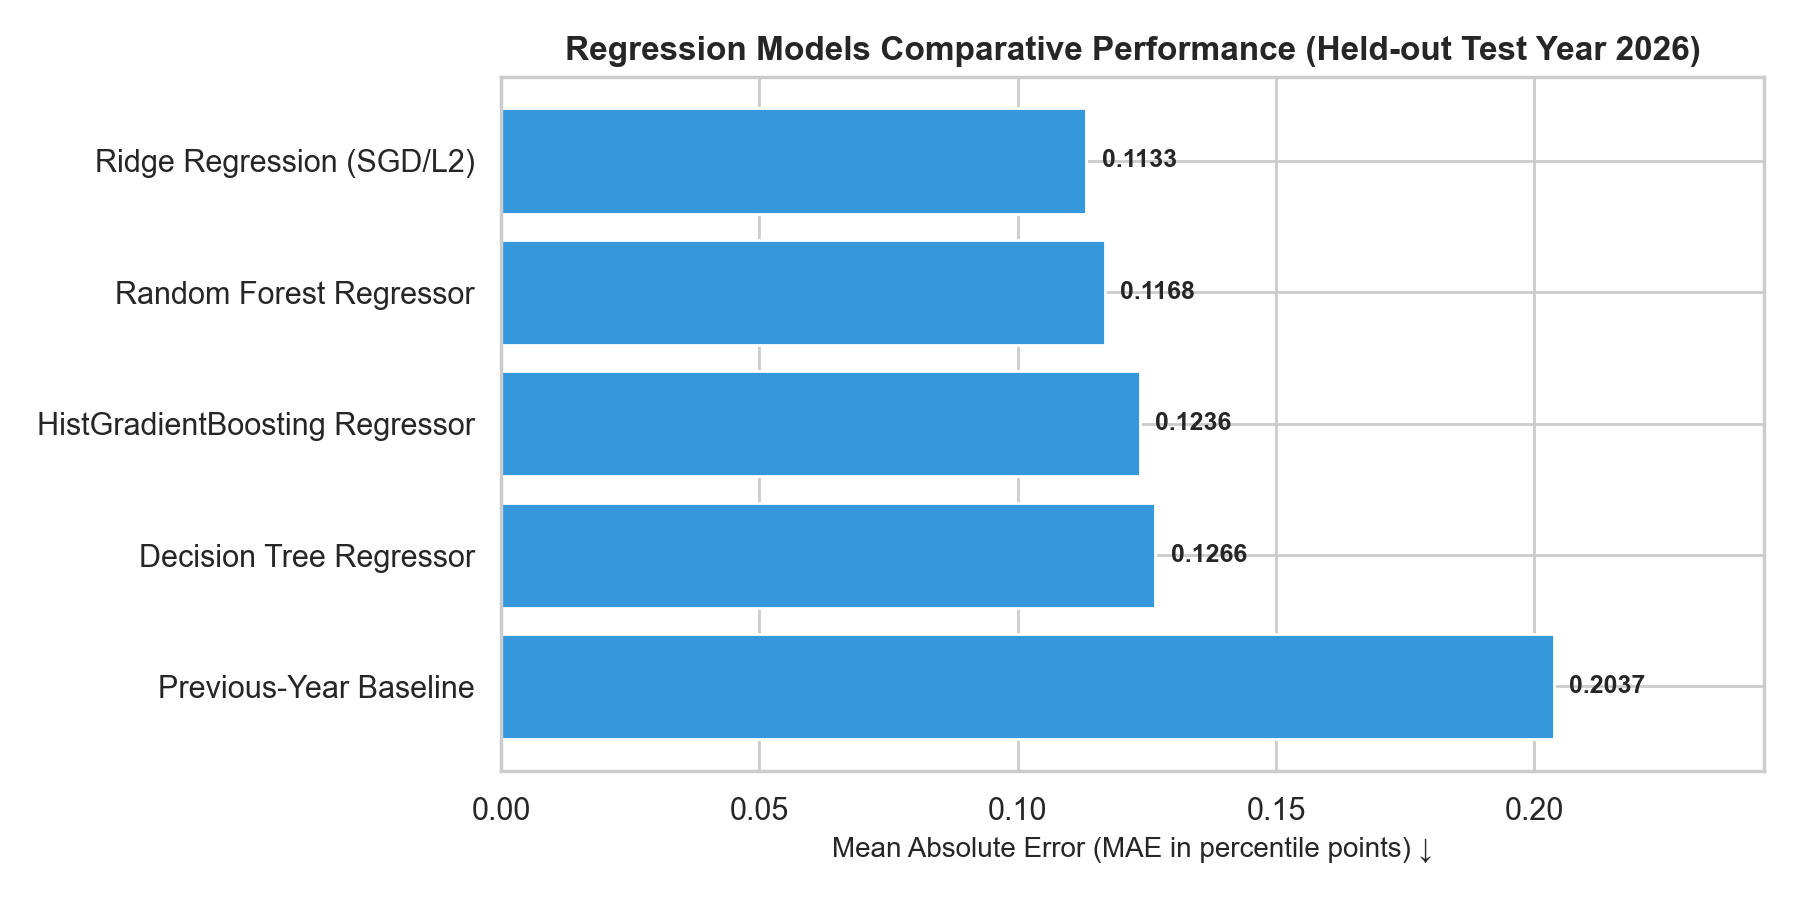

In [1]:
# Step 3: Visualizing Model Comparison Bar Chart
from PIL import Image
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5), dpi=120)
img = Image.open('../report/screenshots/model_comparison_bar.png')
plt.imshow(img)
plt.axis('off')
plt.title('Algorithm Comparison: MAE on Held-Out Test Set (Lower is Better)', fontsize=12, fontweight='bold', pad=10)
plt.show()


In [1]:
# Step 4: Verify serialized production model
import joblib
import json

model = joblib.load('../models/selected_model.joblib')
with open('../models/model_metadata.json') as f:
    meta = json.load(f)

print('Serialized Pipeline Steps:', [step[0] for step in model.steps])
print('Model Metadata:', json.dumps(meta, indent=2))


Serialized Pipeline Steps: ['preprocessor', 'regressor']
Model Metadata: {
  "best_model_name": "Ridge Regression (SGD/L2)",
  "validation_mae": 0.1133,
  "validation_rmse": 0.1415,
  "validation_r2": 0.9996,
  "recommendation_margin": 0.17,
  "forecast_year": "2027-28"
}
